# 01 Synthetic data generation
**CX Advanced Analytics & AI Suite** | all data are synthetic; company and product names are illustrative only.

Two datasets are produced:
1. **AI/ML dataset**: one row per customer account (BecDx labs, N2C Dx ordering practices) with churn and randomized-outreach labels.
2. **Analytics warehouse**: a star schema (7 dimensions, 3 facts) for marketing-mix and CX KPIs.

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd, numpy as np
from IPython.display import Image, display
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
FIG = ROOT / "reports" / "figures"
def show(p, w=950): display(Image(filename=str(FIG / p), width=w))

## 1. AI/ML customer dataset

In [2]:
from cx_suite.data import generate_ml_data
ml = generate_ml_data.main()
ml.head()

[ml-data] 24,000 rows -> data/raw/cx_customer_ml_dataset.csv  churn=16.2% conv_T=17.0% conv_C=12.5%


,customer_id,company,customer_type,product_line,region,account_tier,tenure_months,annual_test_volume,instrument_downtime_hrs_90d,result_turnaround_days,support_tickets_90d,avg_resolution_hrs,nps_score,email_open_rate,portal_logins_90d,rep_visits_90d,webinars_attended_12m,digital_engagement_score,days_since_last_order,order_trend_qoq,contract_days_to_renewal,competitor_present,price_increase_pct,nba_outreach,converted_60d,unsubscribed_60d,churn_12m,true_uplift,true_p_control
0,CUST-000000,C2N Diagnostics,Primary Care,PrecivityAD2 Blood Test,Northeast,C,5,15,NaN,7.4,1,18.9,8.0,0.484,9,1,1,27.0,55,-0.021,535,0,5,1,0,0,0,0.0888,0.1231
1,CUST-000001,Beckman Coulter,Reference Lab,DxI Immunoassay,Southeast,C,67,13741,18.2,NaN,5,9.0,7.0,0.196,4,2,0,11.3,66,0.037,418,0,2,0,0,0,0,0.0076,0.0790
2,CUST-000002,C2N Diagnostics,Neurology Practice,PrecivityAD2 Blood Test,West,C,18,28,NaN,6.9,2,20.5,7.0,0.282,7,2,0,18.4,0,-0.018,95,1,3,1,0,0,0,0.0086,0.0908
3,CUST-000003,C2N Diagnostics,Neurology Practice,PrecivityAD2 Blood Test,Midwest,A,5,72,NaN,6.4,2,18.7,9.0,0.158,4,3,0,12.3,16,0.049,71,0,5,0,0,0,0,0.2452,0.1317
4,CUST-000004,Beckman Coulter,Physician Office Lab,DxI Immunoassay,Midwest,B,48,25003,9.5,NaN,4,12.2,10.0,0.502,7,4,2,30.6,47,-0.041,235,1,2,0,0,0,0,0.0245,0.1656


In [3]:
ml.groupby('company').agg(accounts=('customer_id','count'), churn_rate=('churn_12m','mean'),
    nps=('nps_score','mean'), email_open=('email_open_rate','mean')).round(3)

,accounts,churn_rate,nps,email_open
company,,,,
Beckman Coulter,13150,0.122,7.563,0.304
C2N Diagnostics,10850,0.211,7.517,0.307


Missingness is intentional and meaningful: downtime applies to instrument customers (BEC), turnaround to send-out testing (C2N), and ~16% of accounts never answer NPS surveys.

In [4]:
ml.isna().mean().loc[lambda s: s > 0].round(3)

instrument_downtime_hrs_90d    0.452
result_turnaround_days         0.548
nps_score                      0.161
dtype: float64

In [5]:
# Randomized historical campaign: groups must be balanced on pre-treatment covariates
ml.groupby('nba_outreach')[['tenure_months','email_open_rate','support_tickets_90d','digital_engagement_score']].mean().round(2)

,tenure_months,email_open_rate,support_tickets_90d,digital_engagement_score
nba_outreach,,,,
0,44.35,0.30,3.30,19.89
1,43.67,0.31,3.33,19.93


## 2. Analytics warehouse (star schema)

In [6]:
from cx_suite.data import generate_analytics_data
from cx_suite.analytics import star_schema
generate_analytics_data.main()
t = star_schema.load()
{k: v.shape for k, v in t.items()}

[analytics-data] dim_date=156, dim_brand=3, dim_channel=7, dim_region=5, dim_campaign=63, dim_account=4,000, dim_touchpoint=7, fact_marketing_activity=16,380, fact_orders=2,340, fact_cx_interaction=60,000


{'dim_date': (156, 9),
 'dim_brand': (3, 6),
 'dim_channel': (7, 5),
 'dim_region': (5, 4),
 'dim_campaign': (63, 10),
 'dim_account': (4000, 8),
 'dim_touchpoint': (7, 4),
 'fact_marketing_activity': (16380, 9),
 'fact_orders': (2340, 6),
 'fact_cx_interaction': (60000, 10)}

In [7]:
star_schema.validate(t)

,table,check,passed
0,fact_marketing_activity,grain unique,True
1,fact_marketing_activity,FK date_key -> dim_date,True
2,fact_marketing_activity,FK brand_key -> dim_brand,True
3,fact_marketing_activity,FK region_key -> dim_region,True
4,fact_marketing_activity,FK channel_key -> dim_channel,True
5,fact_marketing_activity,FK campaign_key -> dim_campaign,True
6,fact_marketing_activity,spend_usd >= 0,True
7,fact_marketing_activity,impressions >= 0,True
8,fact_marketing_activity,clicks >= 0,True
9,fact_marketing_activity,engagements >= 0,True


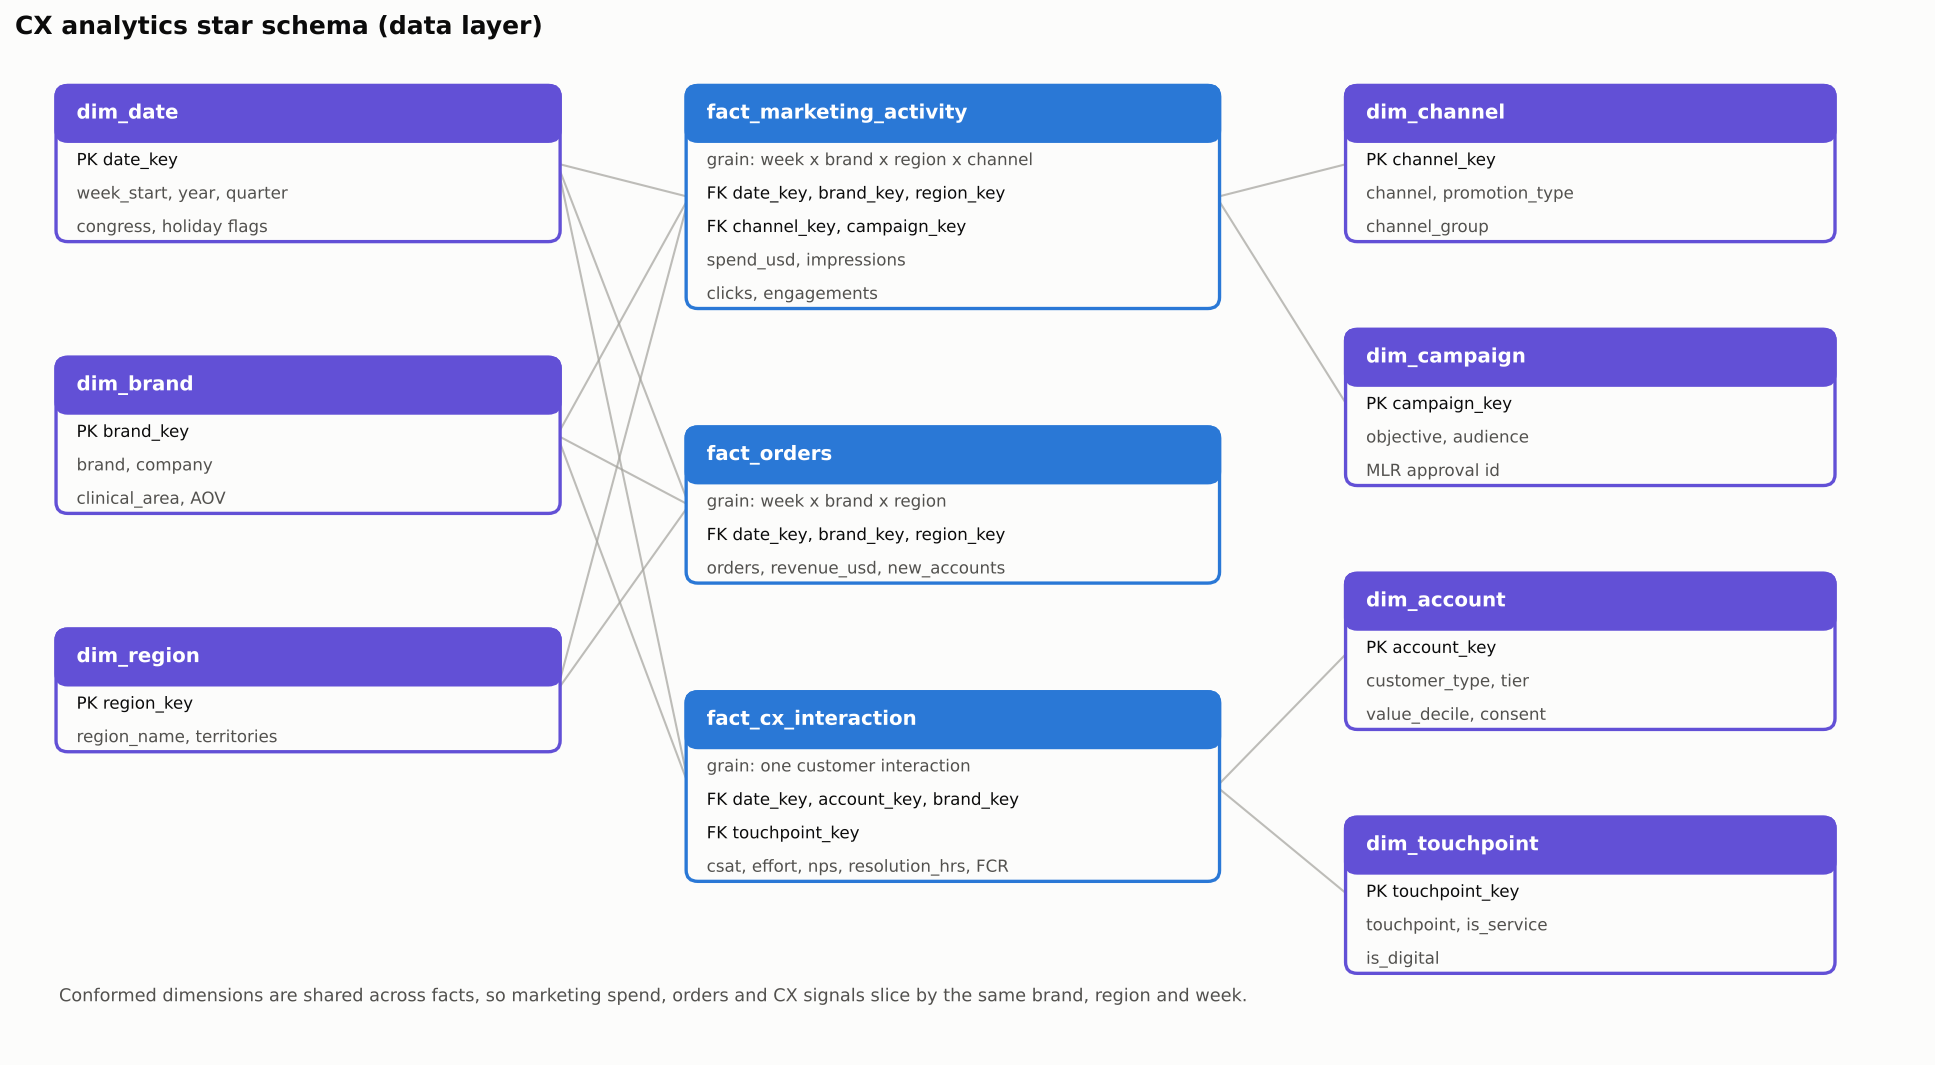

In [8]:
star_schema.draw_er_diagram()
show('analytics/01_star_schema_er_diagram.png')

In [9]:
t['fact_marketing_activity'].merge(t['dim_channel'], on='channel_key').groupby('channel_name').spend_usd.sum().div(3e6).round(2).rename('avg $M / yr')

channel_name
Congress & Trade Shows     3.69
Field Rep Detailing       12.60
HCP / Lab Email            1.13
LinkedIn / Paid Social     1.72
Paid Search                2.60
Peer Webinars              0.96
Programmatic Display       1.77
Name: avg $M / yr, dtype: float64